Course: Master of Data Science & Analytics

Assignment 1: Data Science Lifecycle

Registration Number:S26M19/022

Access Number: B34984


***Importing python libraries and the file upload funstions in the code below***

In [7]:

# Import the required Python libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import the file upload function from Google Colab
from google.colab import files

# Set the display options
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

# Set the visualisation style
sns.set_style('whitegrid')

print("All libraries imported successfully.")


All libraries imported successfully.


The code above successfully imported the following libraries whose functions are;
1. pandas: for data manipulation and analysis
2. numpy: for numerical calculations
3. matplotlib: for creating graphs
4. seaborn: for visualizations
5. files: uploads datasets into google colab.

***I will go ahead and upload the automobile dataset in the code cell below,***

In [8]:

# Upload the automobile dataset

uploaded = files.upload()


Saving automobileEDA.csv to automobileEDA.csv


***Loading the dataset into the pandas dataframe and display the first five records***

In [9]:

# Load the dataset into a Pandas DataFrame

df = pd.read_csv('automobileEDA.csv')

# Display the first five records
df.head()


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


**Displaying 5 rows * 29 columns**

**Data Exploration and cleaning**

In [10]:

# Examine the dimensions of the dataset
print("Dataset dimensions:", df.shape)

# Examine the column names
print("\nColumn names:")
print(df.columns.tolist())

# Examine the data types and non-null counts
print("\nDataset information:")
df.info()


Dataset dimensions: (201, 29)

Column names:
['symboling', 'normalized-losses', 'make', 'aspiration', 'num-of-doors', 'body-style', 'drive-wheels', 'engine-location', 'wheel-base', 'length', 'width', 'height', 'curb-weight', 'engine-type', 'num-of-cylinders', 'engine-size', 'fuel-system', 'bore', 'stroke', 'compression-ratio', 'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price', 'city-L/100km', 'horsepower-binned', 'diesel', 'gas']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 29 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   symboling          201 non-null    int64  
 1   normalized-losses  201 non-null    int64  
 2   make               201 non-null    object 
 3   aspiration         201 non-null    object 
 4   num-of-doors       201 non-null    object 
 5   body-style         201 non-null    object 
 6   drive-wheels       201 non-null    obje

The dataset has 201 rows and 29 columns. The columns run from symboling, normalized-losses to the last column which is gas. And the target variable is price in column 24.

The dataset entails both continouos and catergorical varibles, it has floats, intergers and objects.

interger variables are 8 in number and some of these include; symboling, normalized losses, city-mpg, gas types among others.

Float variables are 11 in number and some of these include; wheel base, length, width, height, price, among others.

objects are 10 in number and some include; make, aspirations, num-of-doors, body-style, drive-wheels, engine location among others.

***Checking for missing varibles inthe code below;***

In [11]:

# Count missing values in each column
missing_values = df.isnull().sum()

# Display only columns with missing values
print("Missing values by column:")
print(missing_values[missing_values > 0])

# Calculate percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nPercentage of missing values:")
print(missing_percentage[missing_percentage > 0])


Missing values by column:
stroke               4
horsepower-binned    1
dtype: int64

Percentage of missing values:
stroke               1.990050
horsepower-binned    0.497512
dtype: float64


The findings indicate that the following;

1. stroke; has 4 missing observations

2. Horsepower-binned; has 1 missing observation


***Checking for duplicate entries***

In [12]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


The dataset has no duplicate entries

There is neeed to handle the missing entries under stroke and horsepower-binned. Since stroke is a numerical float variable, we will replace the missing entries with it's median whereas horsepower-binned missing catergory will be recreated from the existing horse power measurements.

In [13]:

# Create a working copy of the original dataset
df_clean = df.copy()

# Replace missing stroke values with the median
stroke_median = df_clean['stroke'].median()

df_clean['stroke'] = df_clean['stroke'].fillna(stroke_median)

print("Median stroke value:", stroke_median)

# Recreate missing horsepower-binned categories
# using the existing horsepower values
horsepower_bins = np.linspace(
    df_clean['horsepower'].min(),
    df_clean['horsepower'].max(),
    4
)

horsepower_labels = ['Low', 'Medium', 'High']

df_clean['horsepower-binned'] = pd.cut(
    df_clean['horsepower'],
    bins=horsepower_bins,
    labels=horsepower_labels,
    include_lowest=True
)

print("\nMissing values after treatment:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])


Median stroke value: 3.29

Missing values after treatment:
Series([], dtype: int64)


From the output above, the median stroke value was calculated to 3.29 for all the 4 missing values.

The missing horsepower-binned was regenerated using the corresponding horse power measurements.

The output series now confirms that there are no remaining missing values in the dataset.

***Identifying outliers in the dataset***

In [14]:

# Identify continuous numerical variables
continuous_columns = [
    'normalized-losses',
    'wheel-base',
    'length',
    'width',
    'height',
    'curb-weight',
    'engine-size',
    'bore',
    'stroke',
    'compression-ratio',
    'horsepower',
    'peak-rpm',
    'city-mpg',
    'highway-mpg',
    'price',
    'city-L/100km'
]

# Create an empty list to store outlier results
outlier_results = []

# Apply the IQR method to each continuous variable
for column in continuous_columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_results.append({
        'Variable': column,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Lower Bound': round(lower_bound, 2),
        'Upper Bound': round(upper_bound, 2),
        'Outlier Count': len(outliers)
    })

# Display the outlier summary
outlier_summary = pd.DataFrame(outlier_results)

outlier_summary


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count
0,normalized-losses,101.00,137.00,36.00,47.00,191.00,8
1,wheel-base,94.50,102.40,7.90,82.65,114.25,3
2,length,0.80,0.88,0.08,0.68,1.00,1
3,width,0.89,0.92,0.03,0.84,0.98,11
4,height,52.00,55.50,3.50,46.75,60.75,0
5,curb-weight,2169.00,2926.00,757.00,1033.50,4061.50,2
6,engine-size,98.00,141.00,43.00,33.50,205.50,10
7,bore,3.15,3.58,0.43,2.50,4.23,0
8,stroke,3.11,3.41,0.30,2.66,3.86,20
9,compression-ratio,8.60,9.40,0.80,7.40,10.60,27


From the observations above, 16 variables have outliers with compression-ratio having the highest (27) count of outliers followed by stroke (20), price (14) among other variables as the table above.

***Visualizing potential outliers using box plots***

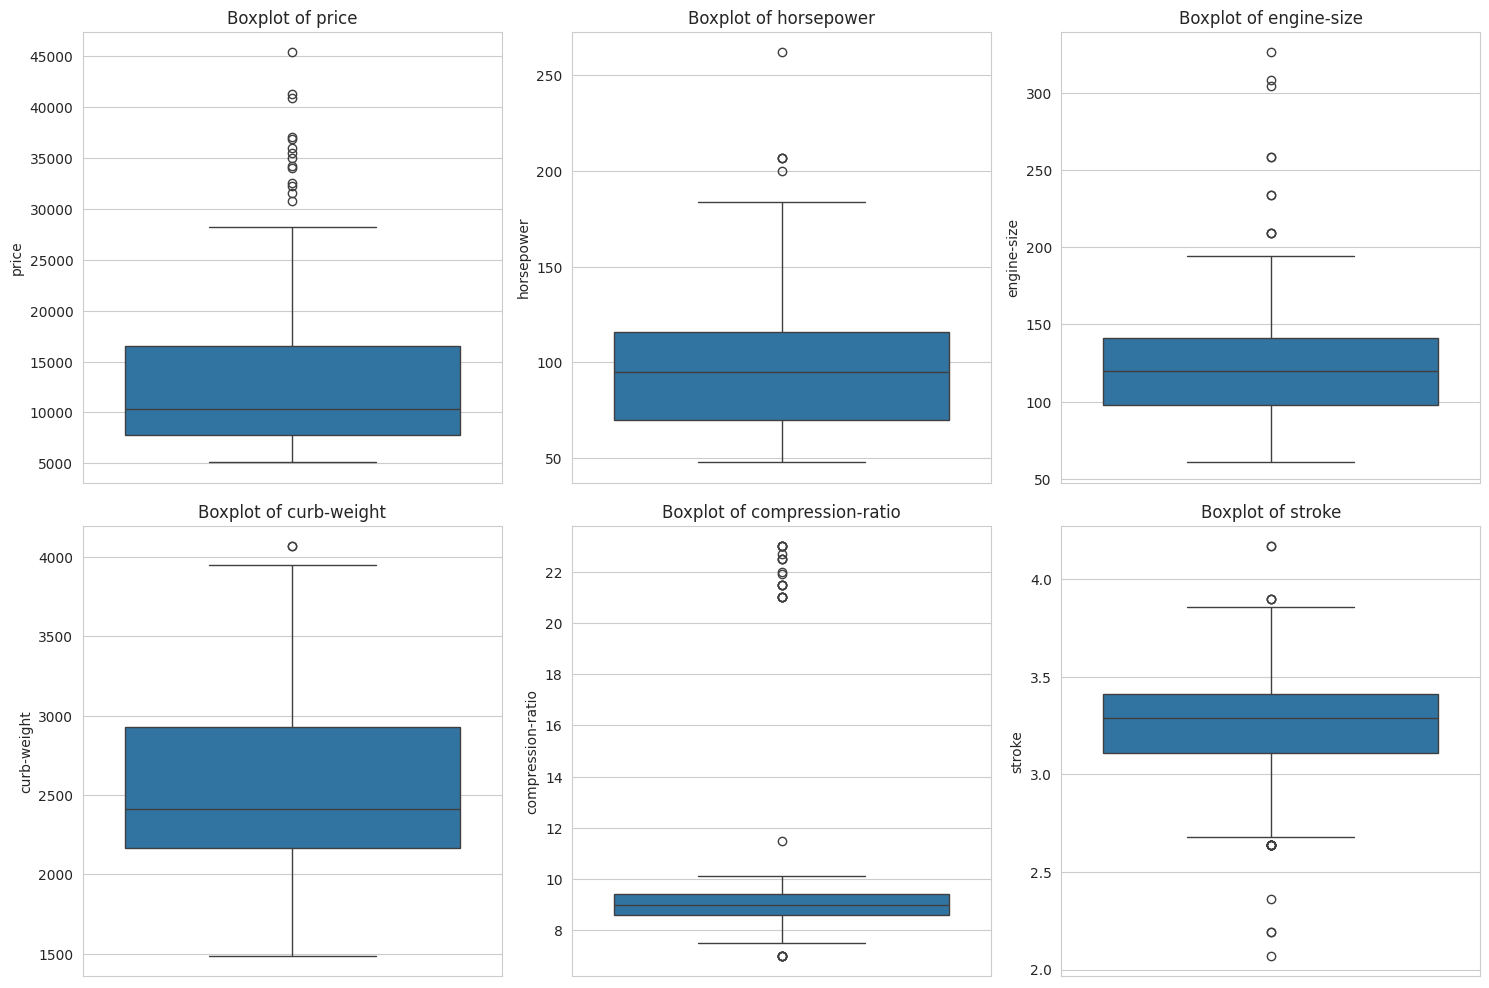

In [15]:

# Visualise potential outliers in selected variables

selected_variables = [
    'price',
    'horsepower',
    'engine-size',
    'curb-weight',
    'compression-ratio',
    'stroke'
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(selected_variables, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df_clean[column])
    plt.title(f'Boxplot of {column}')
    plt.ylabel(column)

plt.tight_layout()
plt.show()


***Interpretaion:***

1. Price: The upper quartile shows many outliers in the price variable with some observations exceeding 45,000. this indicates that a few cars are substantually more expensive than others in the dataset. 14 observations were flagged as potential high-price outliers. These require consideration because they may represent genuine high-performance automobiles rather than treated as data errors.

2. Horsepower: A few horsepower outliers are present in the dataset particularly above 200 horsepower with one observation around 260.

3. Engine size: Several outliers observed with some exceeding 300, this indicates some vehicles having significantly larger engines compared to others in the dataset.

4. Compression-ratio: There is a high concerntration of outliers on the upper quartile beyond 20. This shows the presence of vehicles having unusually high compression ratios.




***The code below is intended to recreate the cleaned dataset from the original data. It replaces the missing stroke values with the earlier calculated median and uses the corresponding horsepower value to determine its category (High since it corresponds to horsepower of 262).***

In [16]:

# Recreate the cleaned dataset from the original data
df_clean = df.copy()

# Replace missing stroke values with the median
df_clean['stroke'] = df_clean['stroke'].fillna(
    df_clean['stroke'].median()
)

# Restore original horsepower classifications
# and classify the missing 262 horsepower observation as High
df_clean['horsepower-binned'] = df_clean[
    'horsepower-binned'
].fillna('High')

# Verify missing values
print("Missing values after correction:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# Verify horsepower categories
print("\nHorsepower category counts:")
print(df_clean['horsepower-binned'].value_counts())


Missing values after correction:
Series([], dtype: int64)

Horsepower category counts:
horsepower-binned
Low       115
Medium     62
High       24
Name: count, dtype: int64


The findings indicate that there are no missing values in any of the variables in the dataset since the stroke observations were replaced by the median (3.29) and the one missing item under horsepower-binned replaced by High catergory.

The cleaning process preserved all 201 observations and the original horsepower classifications that were already available.

***Final validation of the cleaned dataset to check whether there are no missing values and duplicate records before exporting it.***

In [17]:

# Final verification of the cleaned dataset

print("Cleaned dataset dimensions:", df_clean.shape)

print("\nTotal missing values:",
      df_clean.isnull().sum().sum())

print("\nTotal duplicate records:",
      df_clean.duplicated().sum())

print("\nFirst five records of cleaned dataset:")
display(df_clean.head())

print("\nData types:")
print(df_clean.dtypes)


Cleaned dataset dimensions: (201, 29)

Total missing values: 0

Total duplicate records: 0

First five records of cleaned dataset:


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,0.890278,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,0.909722,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,0.919444,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,0.922222,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1



Data types:
symboling              int64
normalized-losses      int64
make                  object
aspiration            object
num-of-doors          object
body-style            object
drive-wheels          object
engine-location       object
wheel-base           float64
length               float64
width                float64
height               float64
curb-weight            int64
engine-type           object
num-of-cylinders      object
engine-size            int64
fuel-system           object
bore                 float64
stroke               float64
compression-ratio    float64
horsepower           float64
peak-rpm             float64
city-mpg               int64
highway-mpg            int64
price                float64
city-L/100km         float64
horsepower-binned     object
diesel                 int64
gas                    int64
dtype: object


***Saving and exporting the cleaned dataset***

In [18]:

# Save the cleaned dataset as a CSV file

df_clean.to_csv('Sanyu Data.csv', index=False)

print("Cleaned dataset saved successfully as Sanyu Data.csv")


Cleaned dataset saved successfully as Sanyu Data.csv


***Downloading the cleaned dataset***

In [20]:

# Download the cleaned dataset

files.download('Sanyu Data.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

***Question 2: Descriptive Statistics and Exploratory Data Analysis***

*Generating summary statistics including; mean, standard deviation, minimum, maximum, upper & lower quartiles for the continouos variables in the code below.*

In [21]:
continuous_features = [
    'normalized-losses',
    'wheel-base',
    'length',
    'width',
    'height',
    'curb-weight',
    'engine-size',
    'bore',
    'stroke',
    'compression-ratio',
    'horsepower',
    'peak-rpm',
    'city-mpg',
    'highway-mpg',
    'price',
    'city-L/100km'
]

summary_statistics = df_clean[continuous_features].describe().T.round(2)

display(summary_statistics)

,count,mean,std,min,25%,50%,75%,max
normalized-losses,201.0,122.00,32.00,65.00,101.00,122.00,137.00,256.00
wheel-base,201.0,98.80,6.07,86.60,94.50,97.00,102.40,120.90
length,201.0,0.84,0.06,0.68,0.80,0.83,0.88,1.00
width,201.0,0.92,0.03,0.84,0.89,0.91,0.92,1.00
height,201.0,53.77,2.45,47.80,52.00,54.10,55.50,59.80
curb-weight,201.0,2555.67,517.30,1488.00,2169.00,2414.00,2926.00,4066.00
engine-size,201.0,126.88,41.55,61.00,98.00,120.00,141.00,326.00
bore,201.0,3.33,0.27,2.54,3.15,3.31,3.58,3.94
stroke,201.0,3.26,0.32,2.07,3.11,3.29,3.41,4.17
compression-ratio,201.0,10.16,4.00,7.00,8.60,9.00,9.40,23.00


***Interpretation of the descriptive statistics***

1. Price: The average automobile price is approximately 13,207.13, while the median is 10,295. The maximum price is 45,400, considerably higher than the median.

2. Engine size: The average engine size is 126.88, with a median of 120 and a maximum of 326. This indicates considerable variation in engine sizes across the vehicles.

3. Horsepower: The average horsepower is 103.41, while the maximum is 262. This shows that the dataset includes vehicles with substantially different engine power capacities.

4. Curb weight: The average vehicle weight is approximately 2,555.67, ranging from 1,488 to 4,066. This indicates differences in vehicle size and weight.

5. Fuel consumption: Average city fuel consumption is 25.18, compared with 30.69 on highways. The dataset therefore shows better average fuel efficiency on highways than in city driving.

6. Vehicle dimensions: The standard deviations for height, width and length are relatively small compared with their respective means, suggesting less variation in these dimensions than in variables such as price, engine size and horsepower.

The mean price (13,207.13) is higher than the median price (10,295). This suggests a positively skewed price distribution.

***Frequency counts for catergorical variables***

In [22]:
categorical_features = [
    'make',
    'aspiration',
    'num-of-doors',
    'body-style',
    'drive-wheels',
    'engine-location',
    'engine-type',
    'num-of-cylinders',
    'fuel-system',
    'horsepower-binned'
]

for column in categorical_features:
    print(f"\nFrequency distribution for {column}:")
    print(df_clean[column].value_counts())


Frequency distribution for make:
make
toyota           32
nissan           18
mazda            17
mitsubishi       13
honda            13
subaru           12
volkswagen       12
volvo            11
peugot           11
dodge             9
mercedes-benz     8
bmw               8
plymouth          7
audi              6
saab              6
porsche           4
chevrolet         3
alfa-romero       3
jaguar            3
isuzu             2
renault           2
mercury           1
Name: count, dtype: int64

Frequency distribution for aspiration:
aspiration
std      165
turbo     36
Name: count, dtype: int64

Frequency distribution for num-of-doors:
num-of-doors
four    115
two      86
Name: count, dtype: int64

Frequency distribution for body-style:
body-style
sedan          94
hatchback      68
wagon          25
hardtop         8
convertible     6
Name: count, dtype: int64

Frequency distribution for drive-wheels:
drive-wheels
fwd    118
rwd     75
4wd      8
Name: count, dtype: int64

Frequ

### Interpretation of Categorical Frequency Distributions

The frequency analysis revealed differences in the representation of vehicle characteristics across the dataset as follows;

Toyota was the most represented automobile manufacturer, with 32 vehicles, followed by Nissan with 18 and Mazda with 17. Sedans were the most common body style accounting for 94 vehicles while hatchbacks accounted for 68.

Front-wheel-drive vehicles dominated the dataset, with 118 observations, compared with 75 rear-wheel-drive and 8 four-wheel-drive vehicles.

Most vehicles had front-mounted engines (198) and four cylinders (157). Standard aspiration was also more common than turbo aspiration with 165 and 36 vehicles respectively.

The analysis further showed that MPFI was the most common fuel system, while the Low horsepower category had the highest representation with 115 vehicles.

Overall, the categorical variables indicate that the dataset is concentrated around particular vehicle characteristics.

***Visualising the distribution of automobile prices***

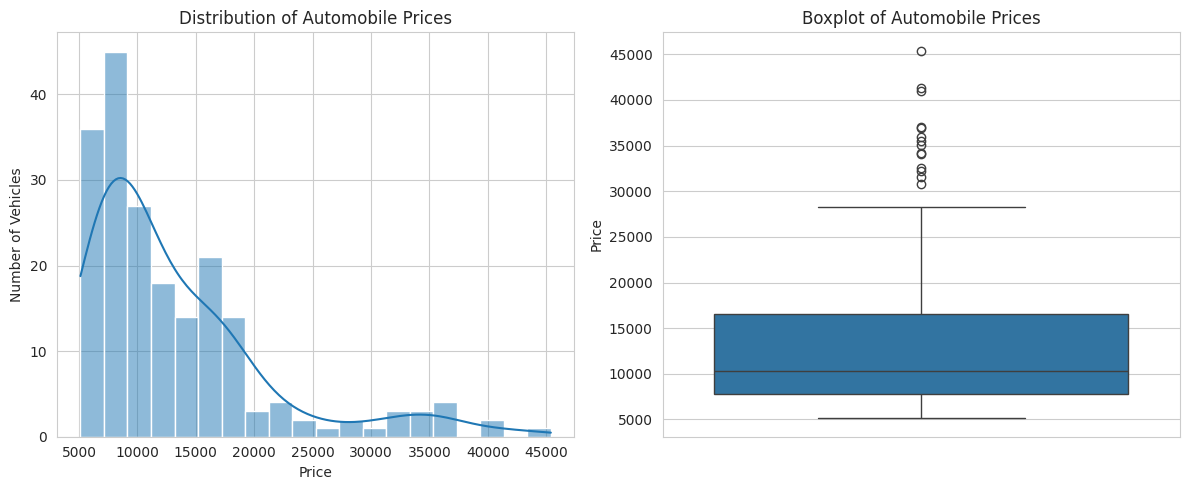

In [23]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df_clean['price'], bins=20, kde=True)
plt.title('Distribution of Automobile Prices')
plt.xlabel('Price')
plt.ylabel('Number of Vehicles')

plt.subplot(1, 2, 2)
sns.boxplot(y=df_clean['price'])
plt.title('Boxplot of Automobile Prices')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

**Interpretation of Automobile Price Distribution**

**Histogram**

It shows that automobile prices are positively skewed, with most vehicles concentrated within the lower price ranges between approximately 5,000 and 15,000. The frequency of vehicles decreases as prices increase, resulting in a long tail towards the higher price values.

**Boxplot**

This further illustrates the distribution, with a median price of approximately 10,295 and the middle 50% of prices falling between 7,775 and 16,500. Several potential outliers appear above the upper range with the highest automobile price reaching 45,400.

These extreme values may represent higher-end or luxury vehicles rather than data-entry errors. Therefore, they are retained for further analysis.

**Visualising other numerical variables**

Investigating the distribution of these 5 numerical variables; Engine size, Horsepower, Curb weight, City mileage and Highway mileage.These might help to explain the differences in automobile prices.

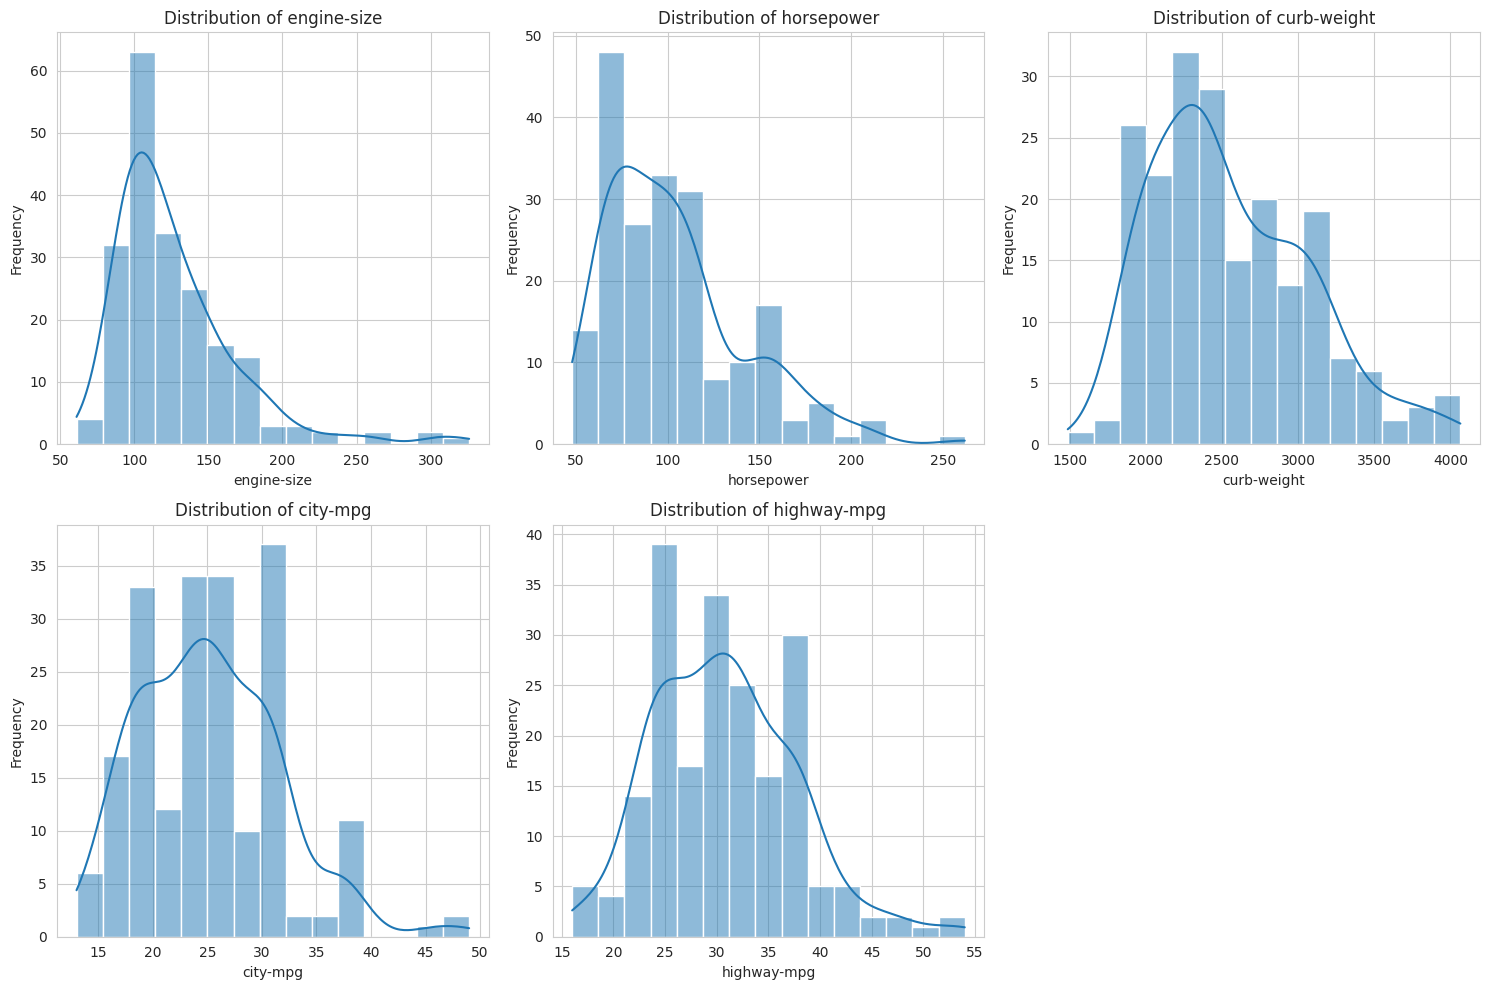

In [24]:
important_features = [
    'engine-size',
    'horsepower',
    'curb-weight',
    'city-mpg',
    'highway-mpg'
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(important_features, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_clean[column], bins=15, kde=True)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

**Interpretation**

1. Distribution of City MPG
The distribution of city-mpg is slightly positively skewed (right-skewed).
Most vehicles achieve between 20 and 30 mpg in city driving.
The highest concentration appears around 24-28 mpg, indicating that most cars have moderate fuel efficiency in urban conditions.
A few vehicles have exceptionally high fuel efficiency (above 40 mpg), creating a long right tail.
This suggests that highly fuel-efficient city vehicles are relatively uncommon.

2. Distribution of Highway MPG
The highway-mpg distribution is also right-skewed.
Most vehicles record between 25 and 38 mpg on highways.
Highway mileage values are generally higher than city mileage values, which is expected because vehicles consume less fuel at steady highway speeds.
There are a few high-efficiency vehicles with highway mileage above 45 mpg.

In conclusion, Vehicles tend to be more fuel-efficient on highways than in cities, with the majority clustered around 30 mpg.

3. Distribution of Engine Size
The engine-size distribution shows a strong positive skewness.
Most vehicles have engine sizes between 90 and 140 cubic inches.
Only a small number of vehicles have very large engines exceeding 200 cubic inches.
The long right tail indicates the presence of larger-engine vehicles, which may represent luxury or performance cars.

Conclusively, the dataset is dominated by vehicles with relatively small to medium-sized engines, while large-engine vehicles are less common.

4. Distribution of Horsepower
The horsepower distribution is positively skewed.
Most vehicles have horsepower values ranging from 70-120 hp.
A few vehicles exhibit very high horsepower (above 180 hp), creating a long right tail.
The concentration at lower horsepower levels suggests that most cars were designed for regular transportation rather than high performance.

5. Distribution of Curb Weight
The curb-weight distribution appears approximately bell-shaped with a slight right skew.
Most vehicles weigh between 2,000 and 3,000 pounds.
The peak occurs around 2,300-2,600 pounds.
A few heavier vehicles exceed 3,500 pounds, forming the right tail.

Most vehicles in the dataset are of moderate weight with relatively few very heavy vehicles.

**Question 3: Grouping and Comparing Automobile Prices**

We will compare average prices by Drive-wheel type and Body style.

*Average price by drive-wheel type*

In [25]:
average_price_drive = (
    df_clean.groupby('drive-wheels')['price']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("Average automobile price by drive-wheel type:")
display(average_price_drive)

Average automobile price by drive-wheel type:


,price
drive-wheels,
rwd,19757.61
4wd,10241.00
fwd,9244.78


***Key findings:***

Rear-wheel-drive vehicles have the highest average price at 19,757.61.

Four-wheel-drive vehicles have an average price of 10,241.00.

Front-wheel-drive vehicles have the lowest average price at 9,244.78.

The analysis revealed differences in average automobile prices across drive-wheel categories. Rear-wheel-drive (RWD) vehicles recorded the highest average price of 19,757.61, followed by four-wheel-drive (4WD) vehicles at 10,241.00. Front-wheel-drive (FWD) vehicles had the lowest average price of 9,244.78.

These findings suggest that rear-wheel-drive vehicles tend to command higher prices than the other drive-wheel categories in the dataset. However, the observed differences may also be influenced by other vehicle characteristics, including engine size, horsepower and manufacturer. Further analysis is therefore necessary to understand the relationships between these characteristics and automobile prices.

***Visualise average price by drive-wheel type***

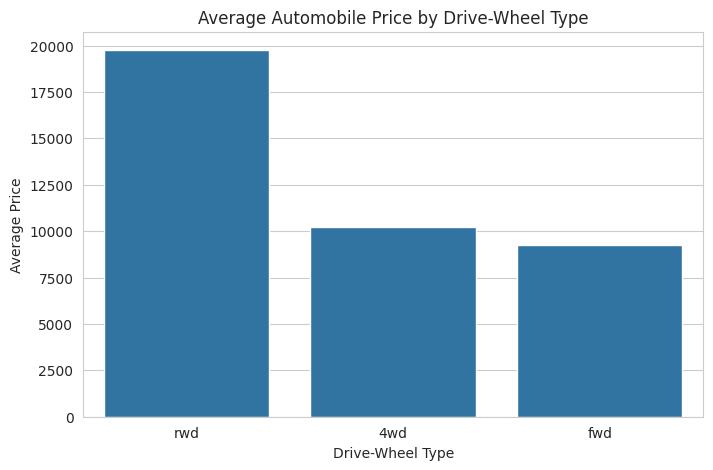

In [26]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=average_price_drive.index,
    y=average_price_drive.values
)

plt.title('Average Automobile Price by Drive-Wheel Type')
plt.xlabel('Drive-Wheel Type')
plt.ylabel('Average Price')
plt.show()

***Interpretation***

The bar chart shows the average automobile price by drive-wheel type.

Rear-wheel drive (RWD) vehicles have the highest average price, at approximately 19,800.

Four-wheel drive (4WD) vehicles have an average price of about 10,200.

Front-wheel drive (FWD) vehicles are the least expensive, with an average price of approximately 9,200.

 Vehicles with rear-wheel drive tend to be significantly more expensive than front-wheel and four-wheel drive vehicles.

***Average automobile price by body style.***

I will compare the average prices of sedans, hatchbacks, wagons, hardtops and convertibles.

In [27]:
average_price_body = (
    df_clean.groupby('body-style')['price']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

print("Average automobile price by body style:")
display(average_price_body)

Average automobile price by body style:


,price
body-style,
hardtop,22208.50
convertible,21890.50
sedan,14459.76
wagon,12371.96
hatchback,9957.44


***Interpretation: ***

*The analysis indicates that premium body styles such as hardtops and convertibles attract significantly higher prices, while hatchbacks and wagons tend to be more affordable. This suggests that vehicle body style is an important factor influencing automobile prices*

***Creating a bar chart to compare the average prices by the car body type***

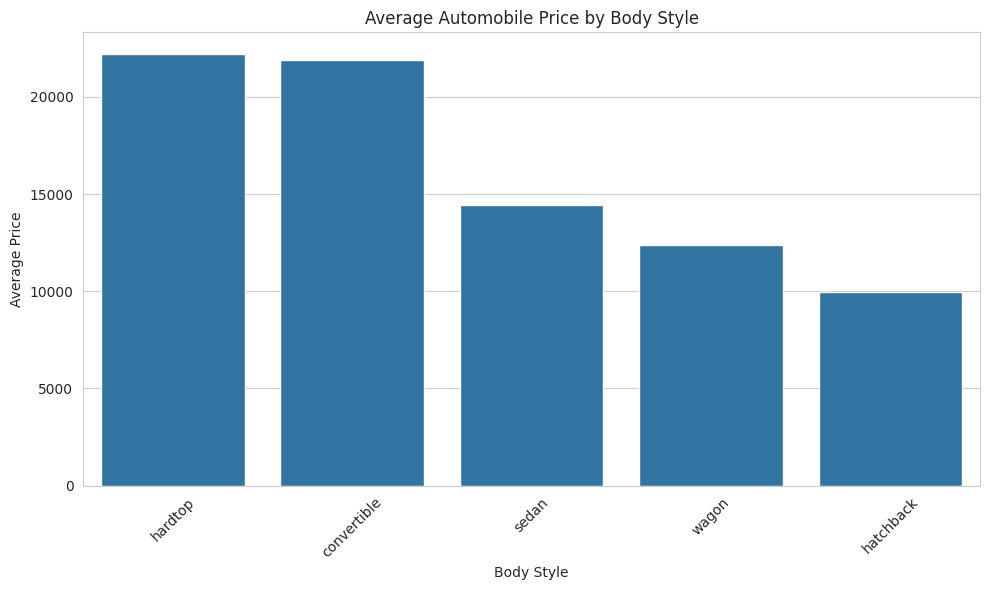

In [28]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=average_price_body.index,
    y=average_price_body.values
)

plt.title('Average Automobile Price by Body Style')
plt.xlabel('Body Style')
plt.ylabel('Average Price')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

The chart indicates that hardtops and convertibles have significantly higher prices, while hatchbacks and wagons tend to be more affordable. This suggests that vehicle body style is an important factor influencing automobile prices



***Identifying the highest and lowest average prices***

In [29]:
print("DRIVE-WHEEL TYPE")
print("Highest average price:")
print(average_price_drive.idxmax(), "-", average_price_drive.max())

print("\nLowest average price:")
print(average_price_drive.idxmin(), "-", average_price_drive.min())


print("\nBODY STYLE")
print("Highest average price:")
print(average_price_body.idxmax(), "-", average_price_body.max())

print("\nLowest average price:")
print(average_price_body.idxmin(), "-", average_price_body.min())

DRIVE-WHEEL TYPE
Highest average price:
rwd - 19757.61

Lowest average price:
fwd - 9244.78

BODY STYLE
Highest average price:
hardtop - 22208.5

Lowest average price:
hatchback - 9957.44


### Conclusion: Grouping and Comparison of Automobile Prices

The grouping analysis revealed differences in average automobile prices across drive-wheel types and body styles. Rear-wheel-drive (RWD) vehicles recorded the highest average price of 19,757.61, whereas front-wheel-drive (FWD) vehicles had the lowest average price of 9,244.78.

Across body styles, hardtop vehicles recorded the highest average price of 22,208.50, while hatchbacks had the lowest average price of 9,957.44. These findings indicate that drivetrain and body style are associated with variations in automobile prices within the dataset.


***Question 4: Analysis of Factors Influencing Automobile Prices***

*Question 4.1: Continuous variables versus automobile price.*

In [30]:
continuous_price_features = [
    'engine-size',
    'horsepower',
    'curb-weight',
    'wheel-base',
    'city-mpg',
    'highway-mpg'
]

price_correlations = (
    df_clean[continuous_price_features + ['price']]
    .corr()['price']
    .drop('price')
    .sort_values(ascending=False)
    .round(3)
)

print("Correlation of continuous variables with automobile price:")
display(price_correlations)

Correlation of continuous variables with automobile price:


,price
engine-size,0.872
curb-weight,0.834
horsepower,0.810
wheel-base,0.585
city-mpg,-0.687
highway-mpg,-0.705


### Interpretation

Correlation analysis was conducted to examine the relationships between selected continuous numerical variables and automobile prices.

Engine size recorded the strongest positive correlation with price (0.872), followed by curb weight (0.834) and horsepower (0.810). Wheelbase also showed a moderate positive correlation of 0.585.

City and highway mileages had negative correlations with automobile price, recording -0.687 and -0.705 respectively. This indicates that vehicles with higher fuel mileage tend to have lower prices within the dataset.

Overall, engine size, curb weight and horsepower emerged as the numerical variables most strongly associated with automobile prices. Fuel efficiency measures also demonstrated notable negative relationships. These results suggest that vehicle performance, weight and fuel consumption are important characteristics to consider when investigating automobile pricing.

***Creating scatterplots to visualize the correlation analysis***

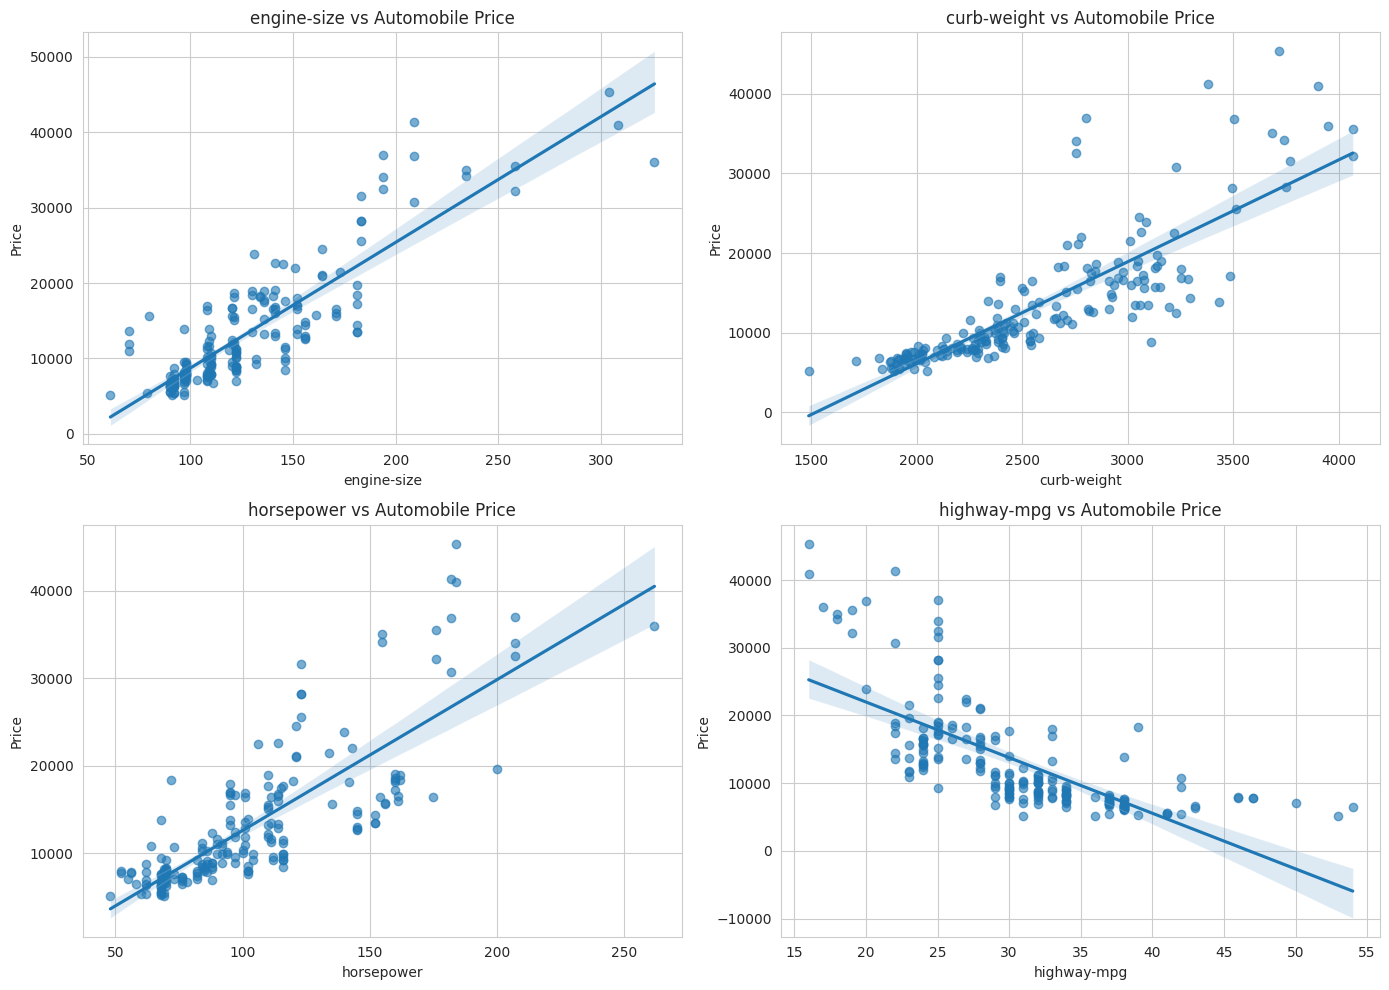

In [31]:
scatter_features = [
    'engine-size',
    'curb-weight',
    'horsepower',
    'highway-mpg'
]

plt.figure(figsize=(14, 10))

for i, column in enumerate(scatter_features, 1):
    plt.subplot(2, 2, i)
    sns.regplot(
        data=df_clean,
        x=column,
        y='price',
        scatter_kws={'alpha': 0.6}
    )
    plt.title(f'{column} vs Automobile Price')
    plt.xlabel(column)
    plt.ylabel('Price')

plt.tight_layout()
plt.show()

***Question 4.2: Relationship Between Categorical Variables and Automobile Price.***

We will investigate whether automobile prices differ across categories such as:

Car make
Body style
Drive-wheel type
Engine type
Aspiration type

Grouped average prices and boxplots will be utlized to compare the categories.

In [33]:
categorical_features = [
    'make',
    'aspiration',
    'num-of-doors',
    'body-style',
    'drive-wheels',
    'engine-location',
    'engine-type',
    'num-of-cylinders',
    'fuel-system',
    'horsepower-binned'
]

for column in categorical_features:
    print(f"\nAverage automobile price by {column}:")
    display(
        df_clean.groupby(column)['price']
        .agg(['mean', 'count'])
        .sort_values(by='mean', ascending=False)
        .round(2)
    )


Average automobile price by make:


,mean,count
make,,
jaguar,34600.00,3
mercedes-benz,33647.00,8
porsche,31400.50,4
bmw,26118.75,8
volvo,18063.18,11
audi,17859.17,6
mercury,16503.00,1
alfa-romero,15498.33,3
peugot,15489.09,11



Average automobile price by aspiration:


,mean,count
aspiration,,
turbo,16254.81,36
std,12542.18,165



Average automobile price by num-of-doors:


,mean,count
num-of-doors,,
four,13498.03,115
two,12818.13,86


... (10 outputs left out)


Average automobile price by fuel-system:


,mean,count
fuel-system,,
mpfi,17605.14,92
idi,15838.15,20
mfi,12964.00,1
4bbl,12145.00,3
spfi,11048.00,1
spdi,10990.44,9
1bbl,7555.55,11
2bbl,7433.20,64



Average automobile price by horsepower-binned:


,mean,count
horsepower-binned,,
High,26320.00,24
Medium,15913.02,62
Low,9011.70,115


### Interpretation of Categorical Variables Against Automobile Price

The analysis revealed variations in average automobile prices across the categorical variables.

Among vehicle manufacturers, Jaguar recorded the highest average price of 34,600, followed by Mercedes-Benz at 33,647, while Chevrolet had the lowest average price of 6,007.

Turbo vehicles had a higher average price (16,254.81) than standard aspiration vehicles (12,542.18).

Hardtops and convertibles recorded the highest average prices among body styles, at 22,208.50 and 21,890.50 respectively while hatchbacks had the lowest average price of 9,957.44. Rear-wheel-drive vehicles also recorded a higher average price (19,757.61) than four-wheel-drive and front-wheel-drive vehicles.

Engine location showed a substantial difference, with rear-engine vehicles averaging 34,528 compared with 12,884.09 for front-engine vehicles. However, only three rear-engine vehicles were represented. Similarly, vehicles with eight cylinders recorded an average price of 38,900, while four-cylinder vehicles averaged 10,303.20. The High horsepower category also had a considerably higher average price (26,320) than the Medium and Low categories.

Overall, the findings suggest that manufacturer, body style, drivetrain, engine characteristics, aspiration and horsepower category are associated with automobile price differences.

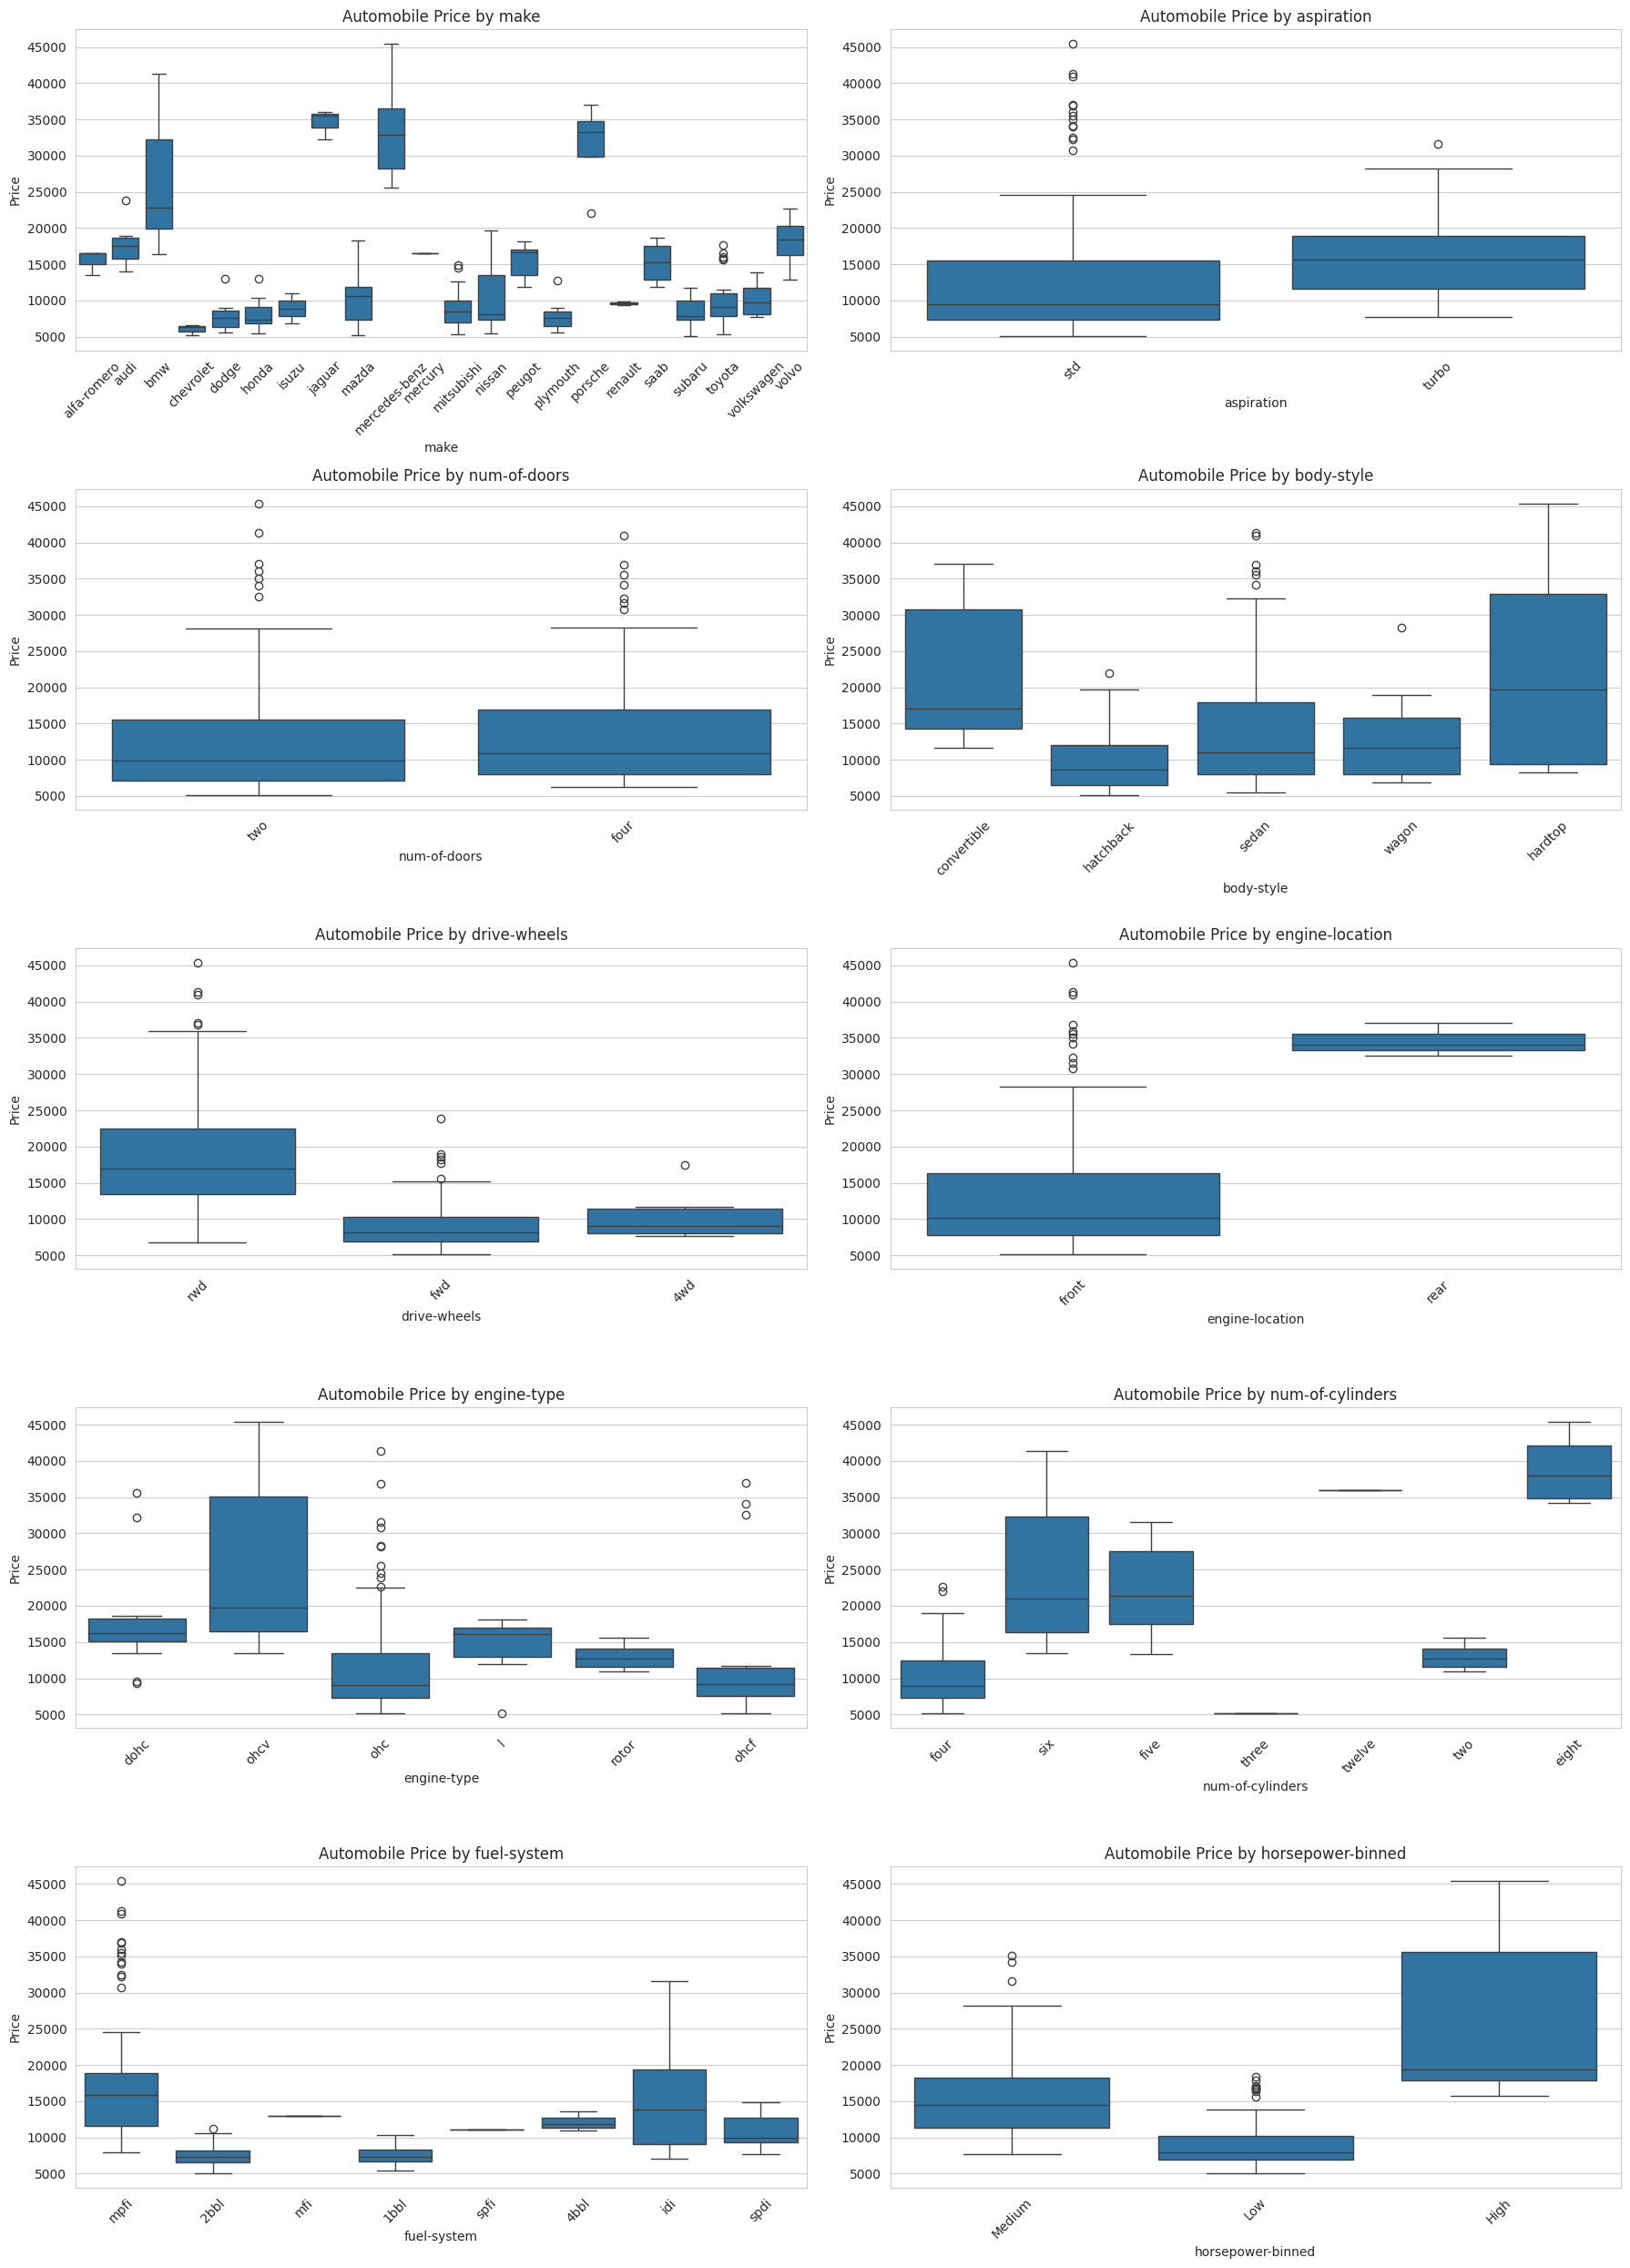

In [34]:
plt.figure(figsize=(18, 25))

for i, column in enumerate(categorical_features, 1):
    plt.subplot(5, 2, i)

    sns.boxplot(
        data=df_clean,
        x=column,
        y='price'
    )

    plt.title(f'Automobile Price by {column}')
    plt.xlabel(column)
    plt.ylabel('Price')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

***Question 4.3: Relationship Between Two Categorical Variables.***

In [35]:
body_drive_table = pd.crosstab(
    df_clean['body-style'],
    df_clean['drive-wheels']
)

print("Relationship between body style and drive-wheel type:")
display(body_drive_table)

Relationship between body style and drive-wheel type:


drive-wheels,4wd,fwd,rwd
body-style,,,
convertible,0,1,5
hardtop,0,1,7
hatchback,1,49,18
sedan,3,55,36
wagon,4,12,9


***Interpretation.***

Front-wheel drive (FWD) is most common among sedans (55) and hatchbacks (49).

Rear-wheel drive (RWD) is most common among sedans (36), followed by hatchbacks (18).

Four-wheel drive (4WD) is relatively uncommon, appearing most frequently among wagons (4) and sedans (3).

Convertibles and hardtops are predominantly rear-wheel drive, with 5 and 7 vehicles respectively.

Overall, the dataset suggests that the distribution of drive-wheel types varies across body styles.

***Visualizing the relationship***

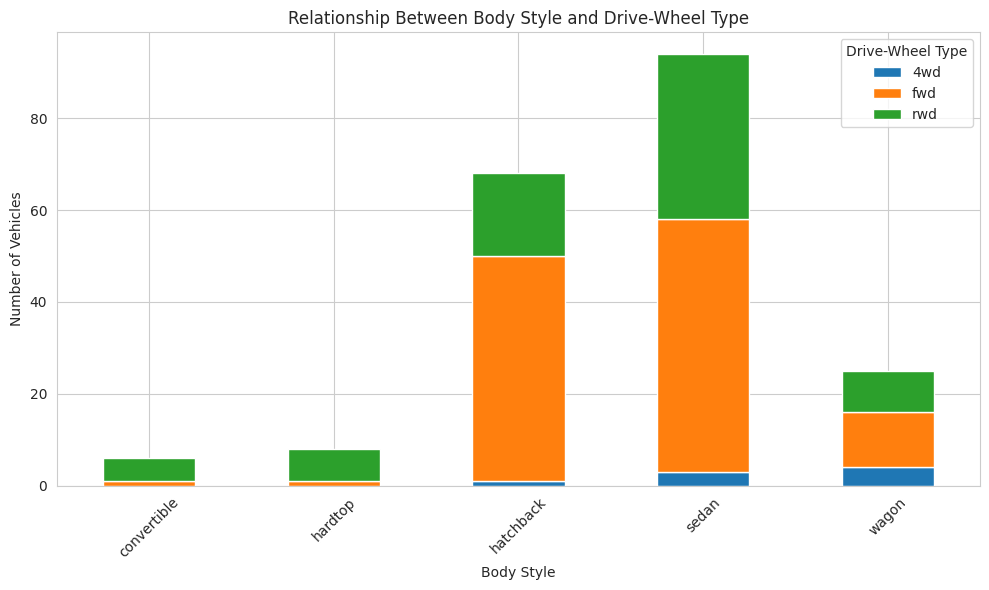

In [36]:
body_drive_table.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Relationship Between Body Style and Drive-Wheel Type')
plt.xlabel('Body Style')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=45)
plt.legend(title='Drive-Wheel Type')
plt.tight_layout()
plt.show()

***Question 5: Feature Selection and Pricing Recommendations***

In [37]:
# Separate the target variable from the predictor variables
X = df_clean.drop(columns=['price'])
y = df_clean['price']

# Convert categorical variables into numerical dummy variables
X_encoded = pd.get_dummies(X, drop_first=True)

# Display the dimensions of the prepared data
print("Predictor dataset shape:", X_encoded.shape)
print("Target variable shape:", y.shape)

# Display the first five rows
display(X_encoded.head())

Predictor dataset shape: (201, 68)
Target variable shape: (201,)


,symboling,normalized-losses,wheel-base,length,width,height,curb-weight,engine-size,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,city-L/100km,diesel,gas,make_audi,make_bmw,make_chevrolet,make_dodge,make_honda,make_isuzu,make_jaguar,make_mazda,make_mercedes-benz,make_mercury,make_mitsubishi,make_nissan,make_peugot,make_plymouth,make_porsche,make_renault,make_saab,make_subaru,make_toyota,make_volkswagen,make_volvo,aspiration_turbo,num-of-doors_two,body-style_hardtop,body-style_hatchback,body-style_sedan,body-style_wagon,drive-wheels_fwd,drive-wheels_rwd,engine-location_rear,engine-type_l,engine-type_ohc,engine-type_ohcf,engine-type_ohcv,engine-type_rotor,num-of-cylinders_five,num-of-cylinders_four,num-of-cylinders_six,num-of-cylinders_three,num-of-cylinders_twelve,num-of-cylinders_two,fuel-system_2bbl,fuel-system_4bbl,fuel-system_idi,fuel-system_mfi,fuel-system_mpfi,fuel-system_spdi,fuel-system_spfi,horsepower-binned_Low,horsepower-binned_Medium
0,3,122,88.6,0.811148,0.890278,48.8,2548,130,3.47,2.68,9.0,111.0,5000.0,21,27,11.190476,0,1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True
1,3,122,88.6,0.811148,0.890278,48.8,2548,130,3.47,2.68,9.0,111.0,5000.0,21,27,11.190476,0,1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True
2,1,122,94.5,0.822681,0.909722,52.4,2823,152,2.68,3.47,9.0,154.0,5000.0,19,26,12.368421,0,1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,True,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,True,False,False,False,True
3,2,164,99.8,0.848630,0.919444,54.3,2337,109,3.19,3.40,10.0,102.0,5500.0,24,30,9.791667,0,1,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,False,False,True,False,False,False,False,True,False,False,False,False,False,False,False,False,True,False,False,False,True
4,2,164,99.4,0.848630,0.922222,54.3,2824,136,3.19,3.40,8.0,115.0,5500.0,18,22,13.055556,0,1,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,False,False,False,True,False,False,False,True


The output above indicates that the dataset is ready for modelling. it shows 201 observations

***Fitting the Random Forest model***

In [38]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42
)

# Train the model
rf_model.fit(X_encoded, y)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


***Ranking the most predictors from the traind model from the highest to the lowest***

In [39]:
# Extract feature importance scores
feature_importance = pd.DataFrame({
    'Feature': X_encoded.columns,
    'Importance': rf_model.feature_importances_
})

# Rank features from most to least important
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Display the top 15 most important predictors
display(feature_importance.head(15).round(4))

,Feature,Importance
0,engine-size,0.6480
1,curb-weight,0.2008
2,highway-mpg,0.0505
3,width,0.0153
4,horsepower,0.0131
5,make_bmw,0.0073
6,normalized-losses,0.0068
7,length,0.0065
8,wheel-base,0.0061
9,compression-ratio,0.0060


**Interpretation**

The Random Forest feature-selection method identified engine size as the most important predictor of automobile prices, with an importance score of 0.6480 (64.8%). Curb weight was the second most important predictor, contributing 0.2008 (20.08%), followed by highway fuel efficiency at 0.0505 (5.05%). Other variables, including vehicle width, horsepower and vehicle make had smaller importance scores.

These findings suggest that engine size and vehicle weight play important roles in predicting automobile prices within this dataset. The results are also consistent with the earlier correlation analysis, which showed strong positive relationships between price and engine size, curb weight and horsepower.


***Visualization of thr top 10 predictors of price***

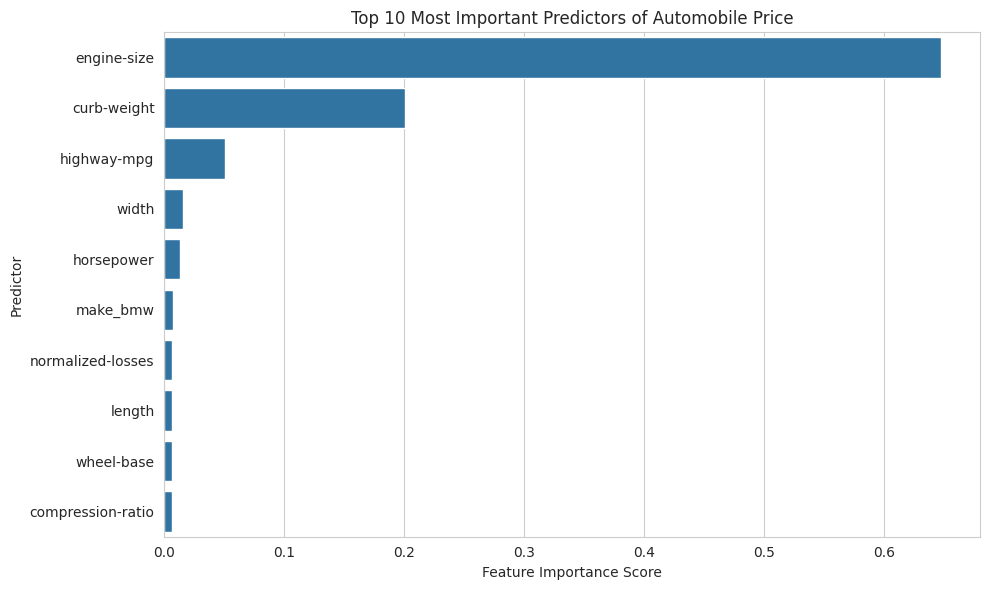

In [40]:
# Select the top 10 most important predictors
top_features = feature_importance.head(10)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title('Top 10 Most Important Predictors of Automobile Price')
plt.xlabel('Feature Importance Score')
plt.ylabel('Predictor')
plt.tight_layout()
plt.show()

**Recommendation**

Based on the analysis, automobile dealers should adopt a data-driven pricing approach supported by predictive modelling techniques such as Random Forest Regression. The model can help estimate appropriate vehicle prices using characteristics identified in the dataset.

Dealers should give particular attention to engine size and curb weight because these were the two strongest predictors of automobile prices. Highway fuel efficiency, horsepower, vehicle dimensions and manufacturer should also be considered when determining prices.

As a practise, dealers should combine model-generated price estimates with other market factors, including vehicle age, mileage, physical condition, maintenance history, customer demand, location and prevailing market prices. The predictive model should be periodically updated using recent vehicle sales data to maintain its relevance and accuracy.

This approach can support more consistent, evidence-based pricing decisions, reduce overpricing/underpricing, improve competitiveness and help dealers maximise revenue while remaining responsive to market conditions.